In [1]:
from requirements import *
import ternary
from utils.pl.plot_ternary import format_tax, plot_ternary, ternary_kde
from utils.tl.deg import runDEseq
from utils.tl.runSAND_transcript import runSAND_transcript

# Figure 3


In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## For immune aggregate identification see SAND.ipynb

## Figure 3c. Ternary density plots: Control / MDS small / MDS large immune aggregates

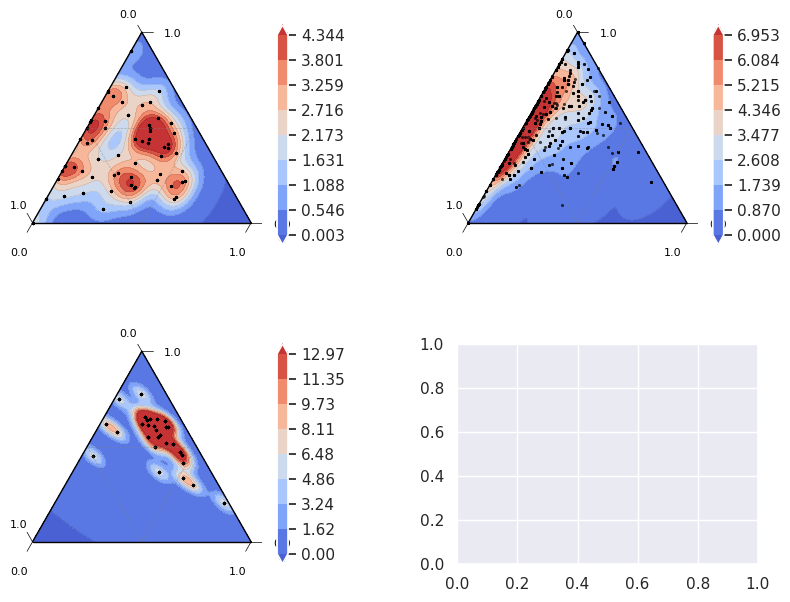

In [27]:
from matplotlib.colors import LinearSegmentedColormap as lsc
matplotlib.rcParams['pdf.fonttype'] = 42
cmap = cmr.get_sub_cmap('coolwarm', 0.05, 0.95)
fig, axes = plt.subplots(
    2, 2,
    figsize=(9.5, 7), 
    gridspec_kw={'hspace':0.45, 'wspace':0.45}
)

tls = adata_xenv1[(adata_xenv1.obs['in_tls'] == 'Yes')]
tls = tls[tls.obs['ct_general'].isin(['T Cell','B Cell'])]
tls.obs['ct_tls'] = [str(x) for x in tls.obs['ct_general']]
tls.obs['ct_tls'][tls.obs['ct_refined'].isin(['CD4 Memory', 'CD4 Naive/Central Memory','CD4 Treg'])] = 'CD4 T'
tls.obs['ct_tls'][tls.obs['ct_refined'].isin(['CD8 Memory', 'CD8 Naive'])] = 'CD8 T'
tls = tls[tls.obs['ct_tls'].isin(['CD4 T','CD8 T','B Cell'])]
df = pd.crosstab(index=tls.obs['tls'], columns=tls.obs['ct_tls']).apply(lambda x: x/x.sum(), axis=1)
tls_size = adata_xenv1[~(adata_xenv1.obs['in_tls'] == 'No')].obs['tls'].value_counts().to_dict()
df['size'] = [tls_size[x] for x in df.index]
di = dict(zip(adata_xenv1.obs['tls'], adata_xenv1.obs['diagnosis']))
df['type'] = [di[x] for x in df.index]
df['ptsz'] = 1
df = df[df['type'] != 'Control-TP']
df['diagnosis'] = df['type']
df['type'] = [x.split('-')[0] for x in df['type']]
df

dfs = [df[(df['size'] < 100) & (df['type'] == 'Control')].loc[:, ['B Cell','CD4 T','CD8 T']],
       df[(df['size'] < 100) & (df['type'] == 'MDS')].loc[:, ['B Cell','CD4 T','CD8 T']],
       df[(df['size'] >= 100) & (df['type'] == 'MDS')].loc[:, ['B Cell','CD4 T','CD8 T']]]
for i, tmp in enumerate(dfs):
    currplt= plot_ternary(tmp.values, cmap, ['B Cell','CD4 T','CD8 T'], axes.flat[i])
    fig.colorbar(currplt, ax = axes.flat[i])


## Figure 3d. Cytokine clusters within B-cell-rich immune aggregates (clustered heatmap)


In [22]:
## Get Xenium output paths

BASE = '/data1/greenbab/users/zhangb2/xenium_files'

def region_key(name):
    """'output__<a>__<b>_<c>...' -> 'region<c>_<a>'"""
    _, a, b = name.split('__')[:3]
    return f"region{b.split('_')[1]}_{a}"

dir_di = {}  # key is region, value is data directory

review_dir = f'{BASE}/review_samples/v1'
for f in os.listdir(review_dir):
    if f.startswith('output'):
        dir_di[region_key(f)] = f'{review_dir}/{f}/'

baysor_dir = f'{BASE}/baysor'
for f in os.listdir(baysor_dir):
    if f.startswith('output'):
        dir_di[region_key(f)] = f'{baysor_dir}/{region_key(f)}/xeniumout/outs/'

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0011549/xeniumout/outs/


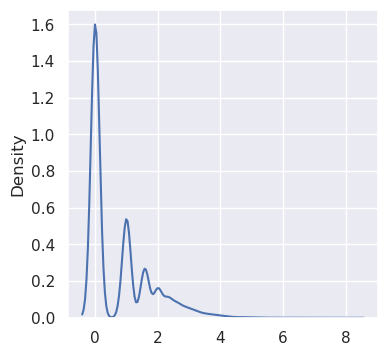

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0011552/xeniumout/outs/


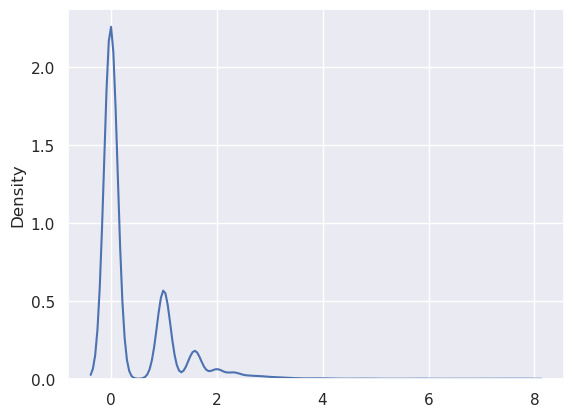

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0011552/xeniumout/outs/


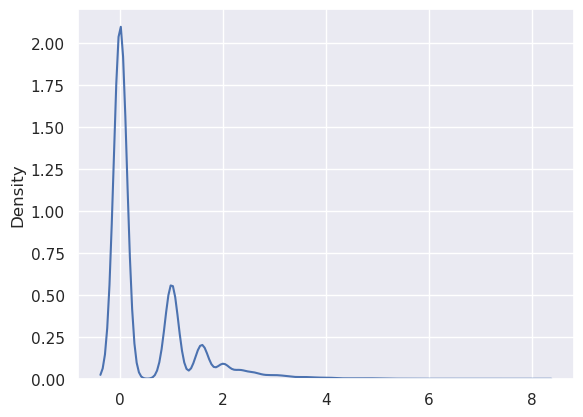

/data1/greenbab/users/zhangb2/xenium_files/baysor/region3_0011552/xeniumout/outs/


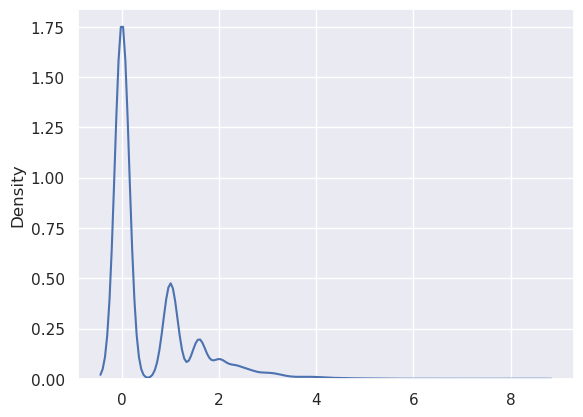

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027612/xeniumout/outs/


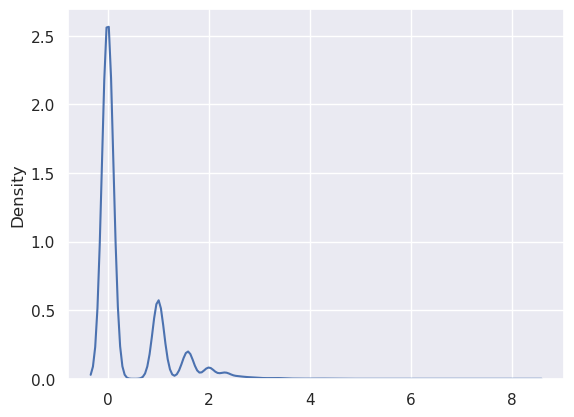

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027609/xeniumout/outs/


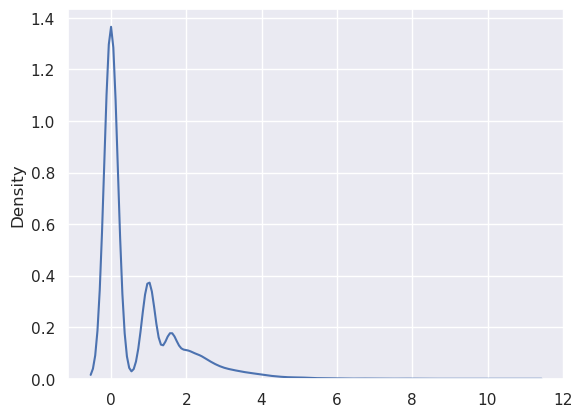

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0015400/xeniumout/outs/


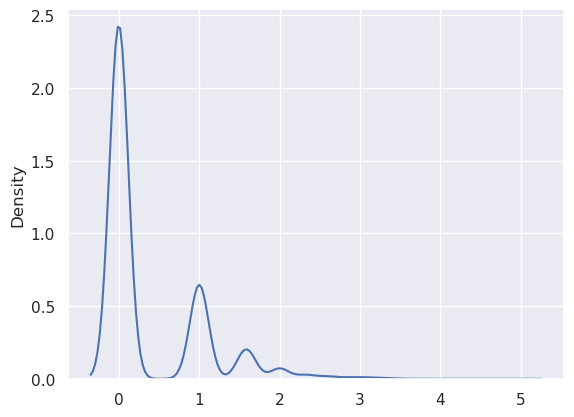

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0015399/xeniumout/outs/


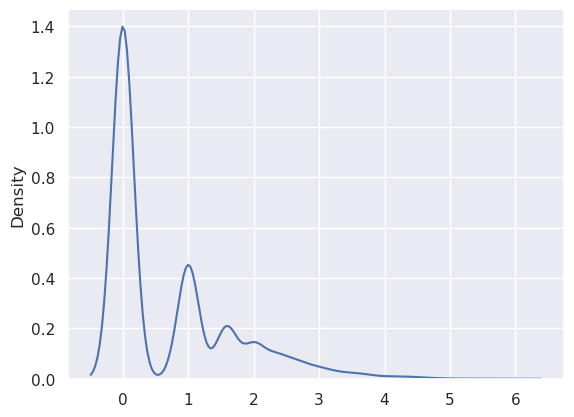

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0027860/xeniumout/outs/


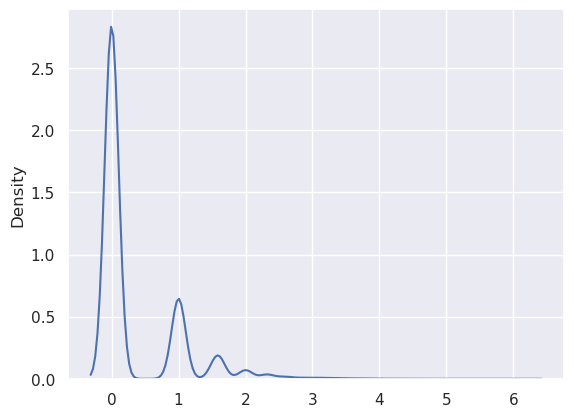

/data1/greenbab/users/zhangb2/xenium_files/baysor/region2_0027861/xeniumout/outs/


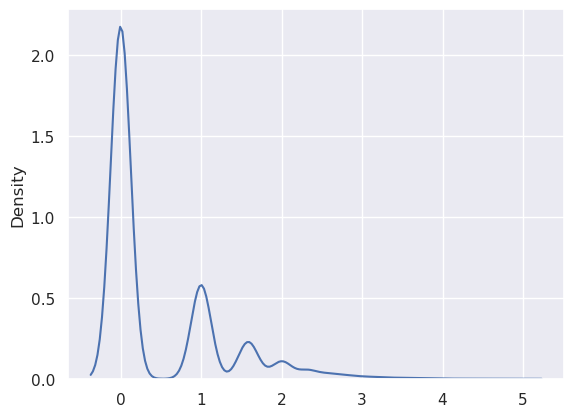

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0043106/xeniumout/outs/


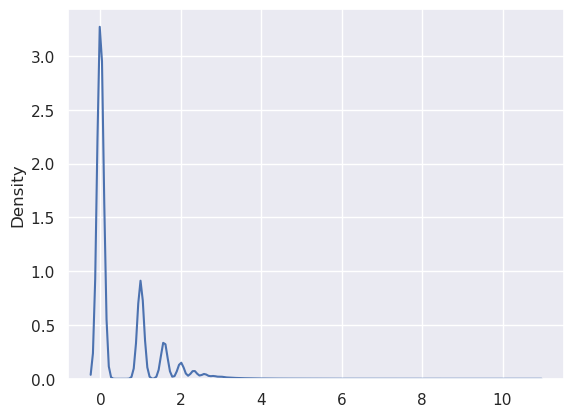

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0043114/xeniumout/outs/


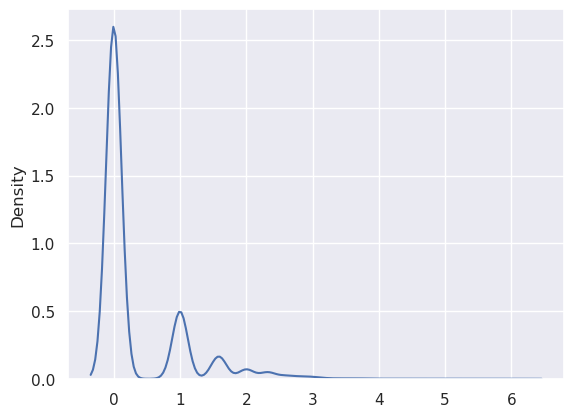

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0036509/xeniumout/outs/


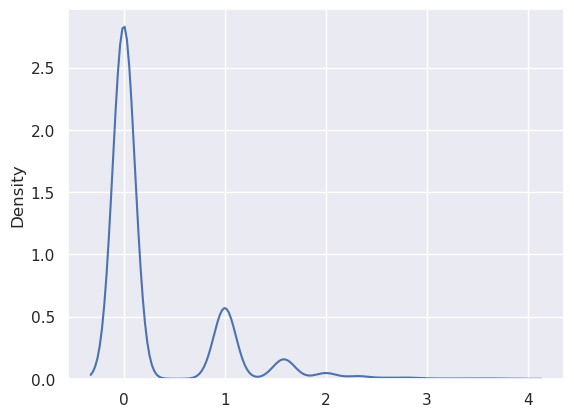

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0036579/xeniumout/outs/


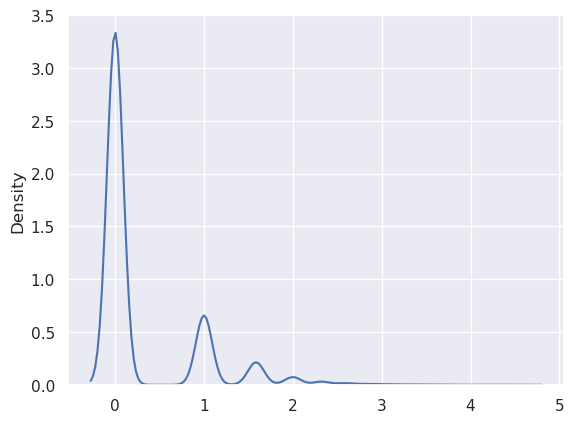

/data1/greenbab/users/zhangb2/xenium_files/baysor/region1_0042581/xeniumout/outs/


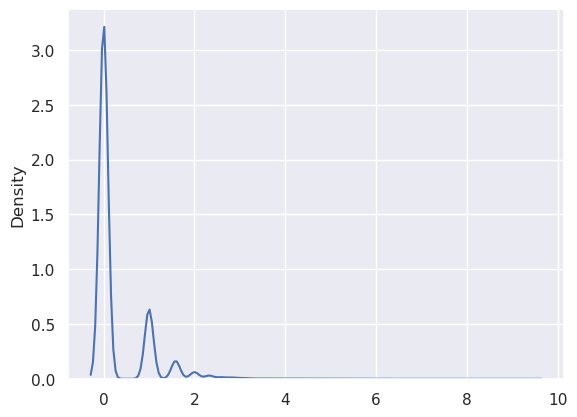

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0033583__Region_1__20250604__183844/


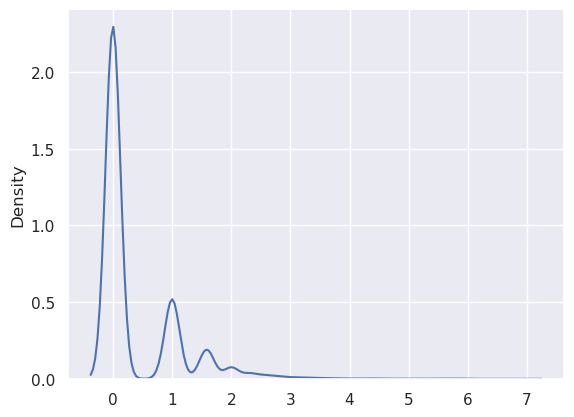

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0033583__Region_2__20250604__183844/


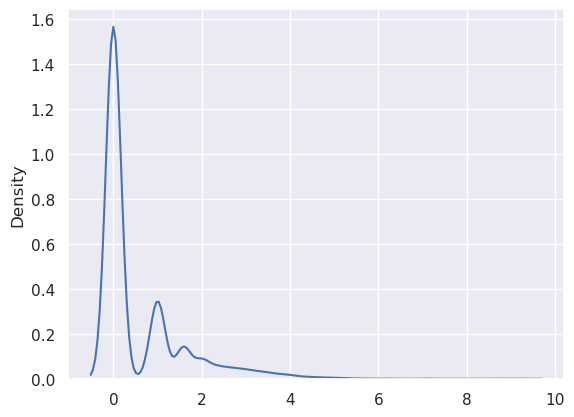

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0042591__Region_2__20250305__185108/


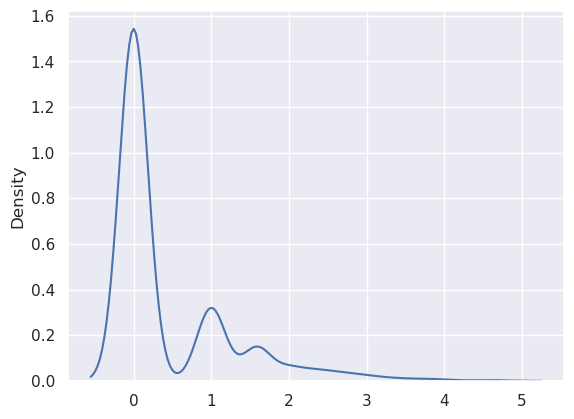

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0042592__Region_1__20250305__185108/


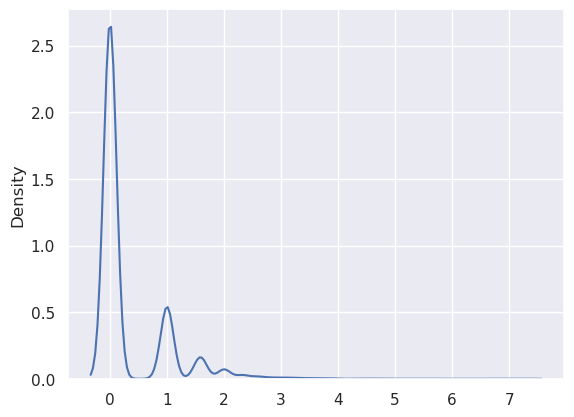

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0064838__Region_1__20250604__183844/


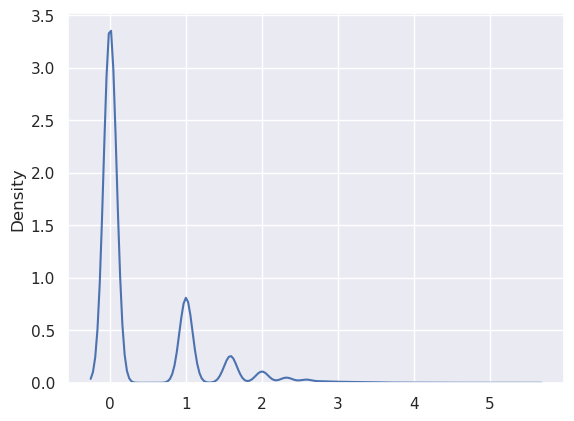

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0064838__Region_2__20250604__183844/


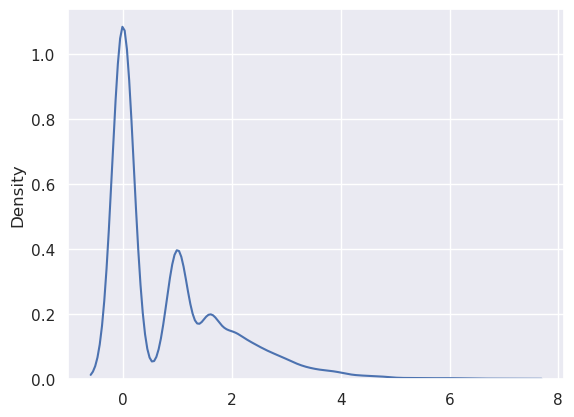

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065604__Region_1__20250523__144423/


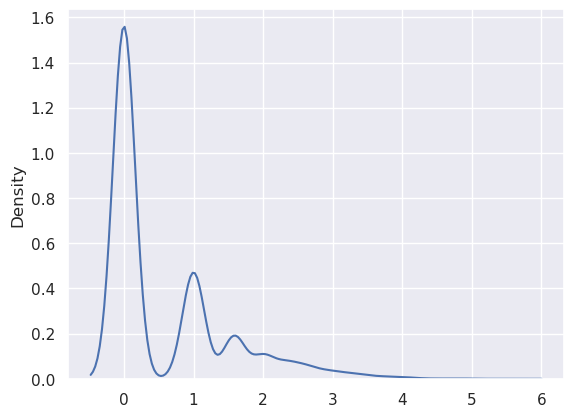

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065604__Region_4__20250523__144423/


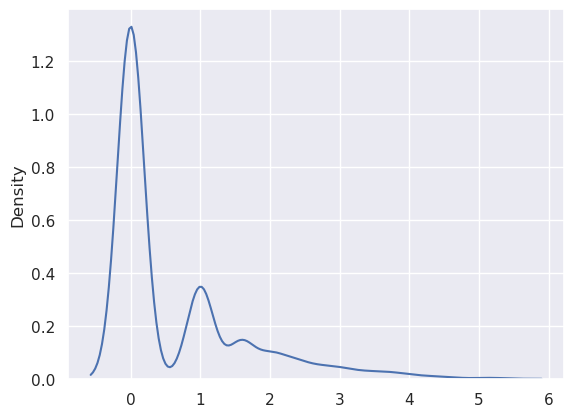

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065607__Region_1__20250523__144423/


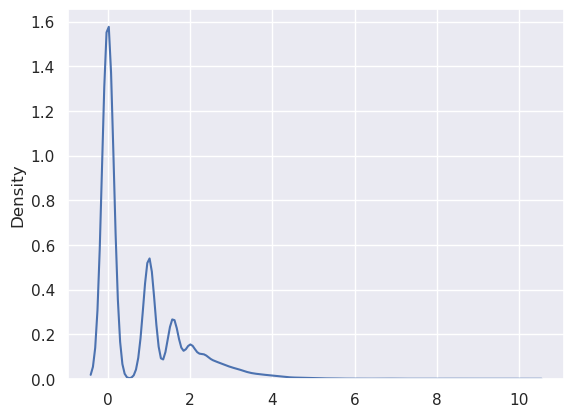

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0065607__Region_2__20250523__144423/


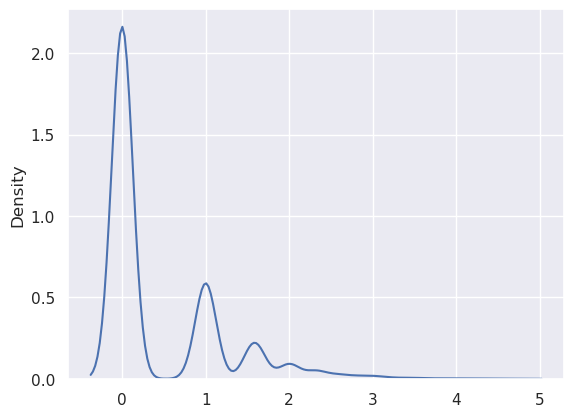

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069145__Region_1__20250801__184414/


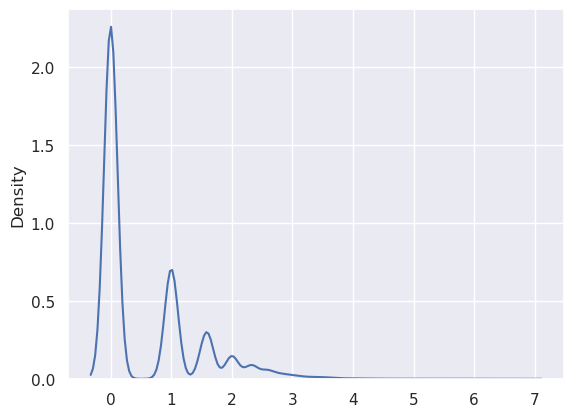

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069145__Region_2__20250801__184414/


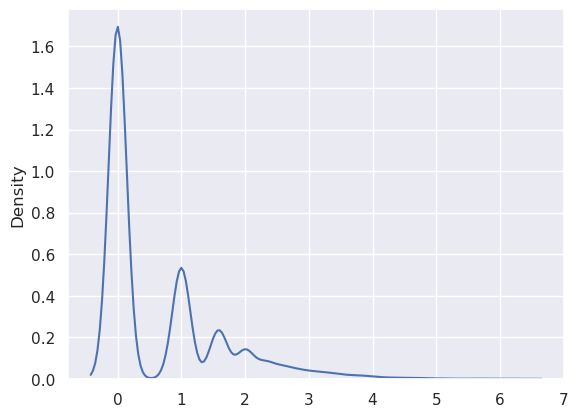

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069146__Region_1__20250801__184414/


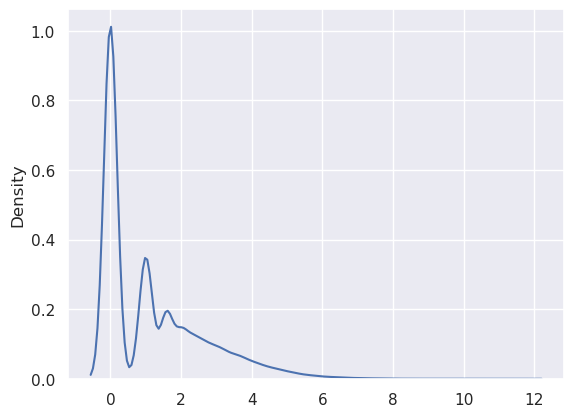

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069146__Region_2__20250801__184414/


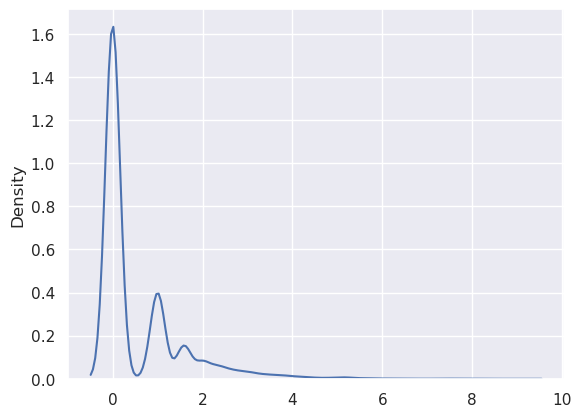

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069319__Region_1__20250822__183944/


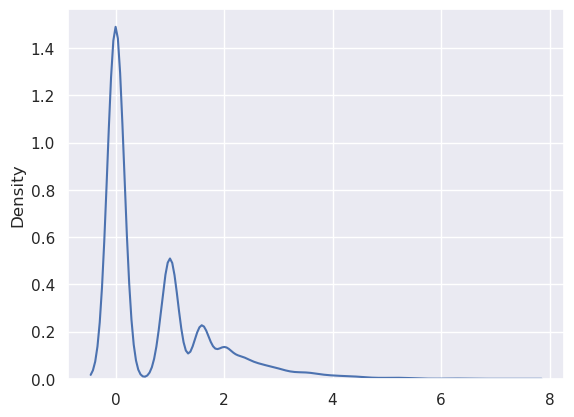

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069319__Region_2__20250822__183944/


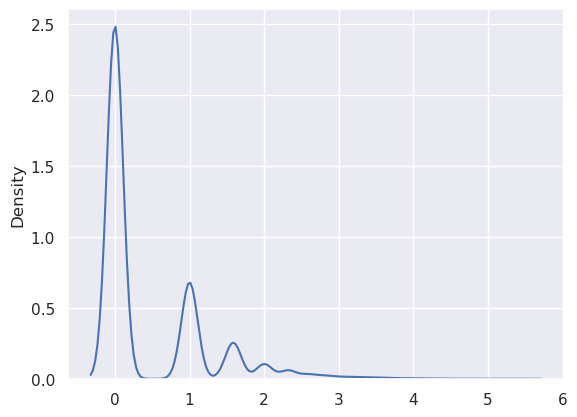

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069320__Region_1__20250822__183944/


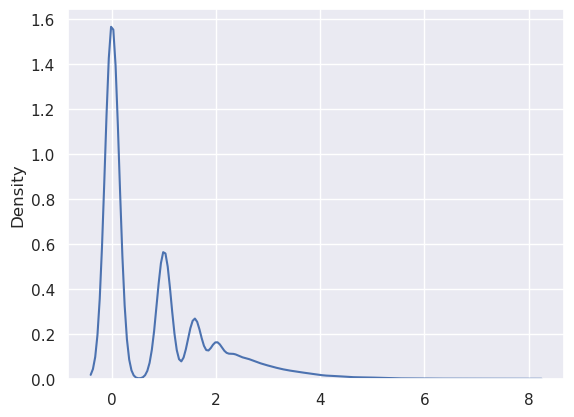

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069320__Region_2__20250822__183944/


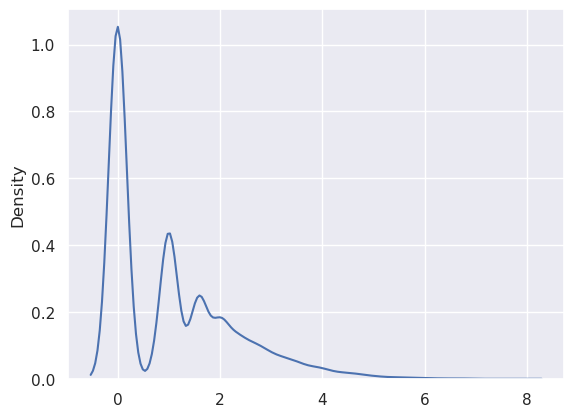

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069330__Region_1__20250815__192418/


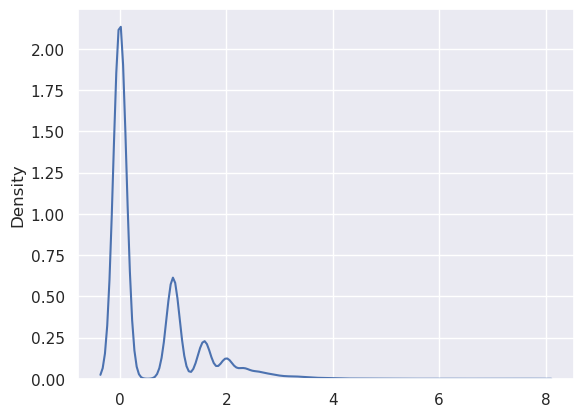

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069331__Region_1__20250815__192418/


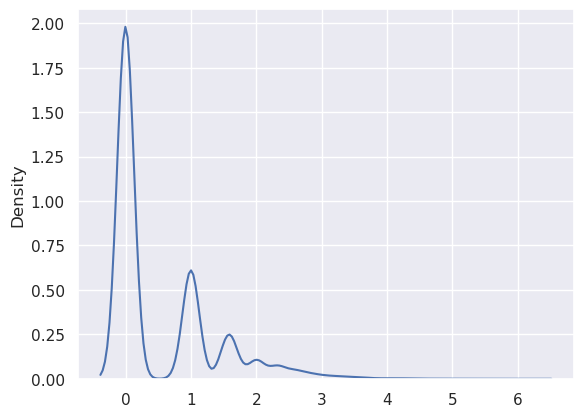

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069670__Region_1__20250808__172051/


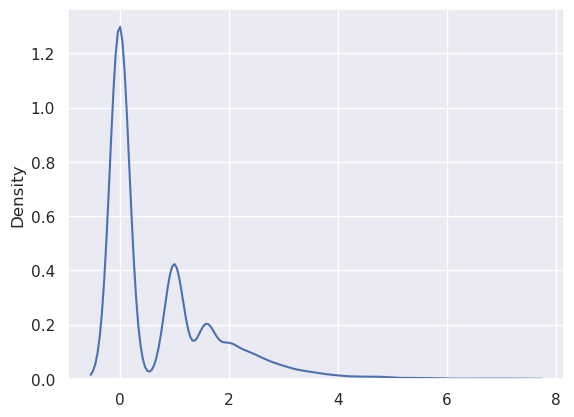

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069737__Region_1__20250808__172052/


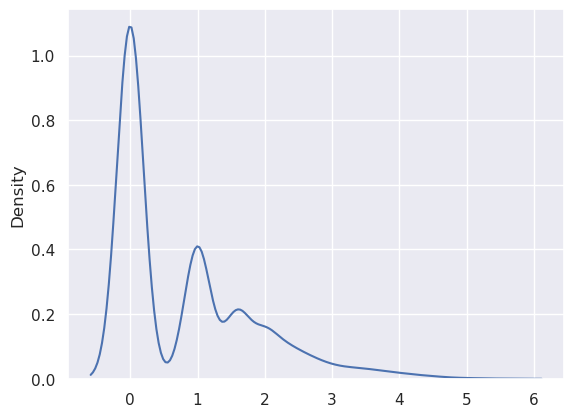

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069737__Region_2__20250808__172052/


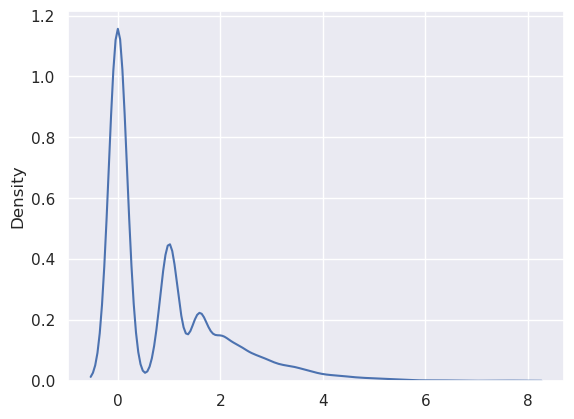

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069187__Region_1__20250808__172538/


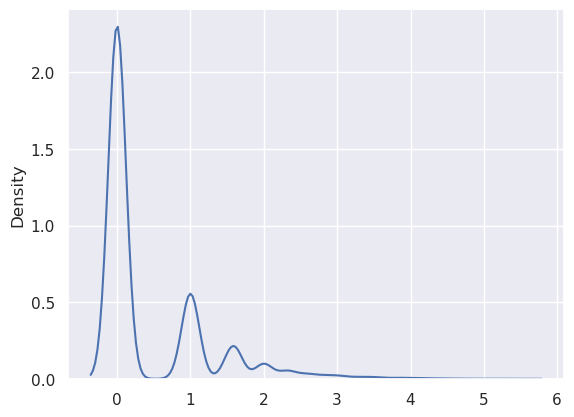

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069478__Region_1__20250815__191843/


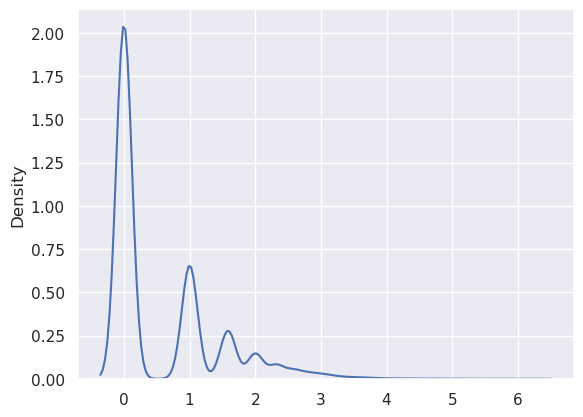

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069478__Region_2__20250815__191843/


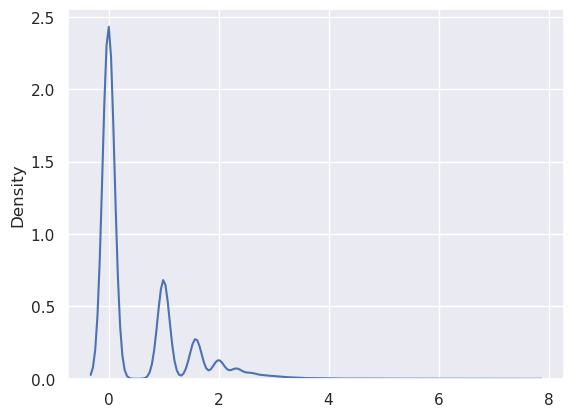

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069480__Region_1__20250815__191843/


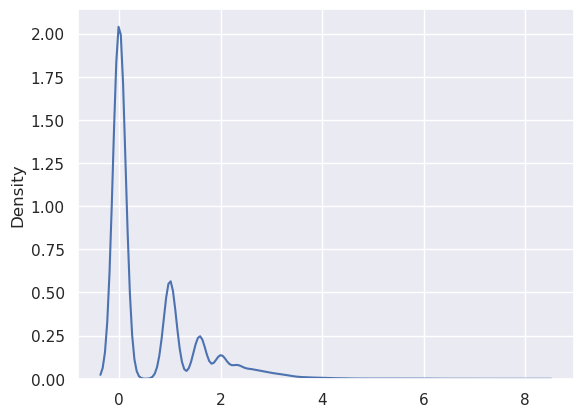

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069594__Region_1__20250822__185706/


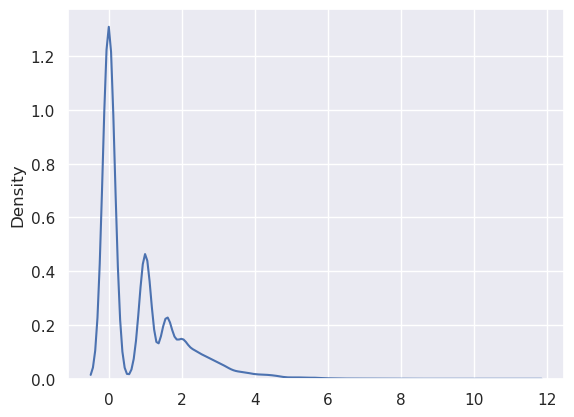

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069594__Region_2__20250822__185707/


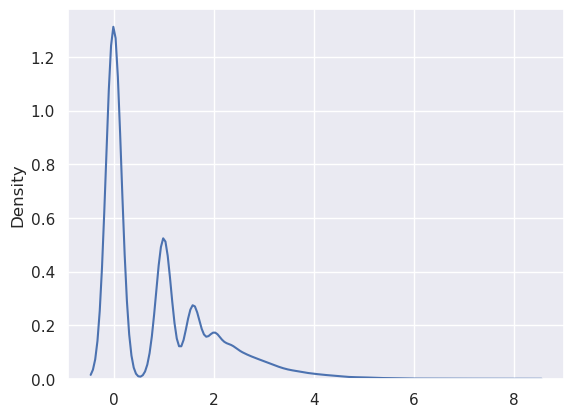

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069595__Region_1__20250822__185707/


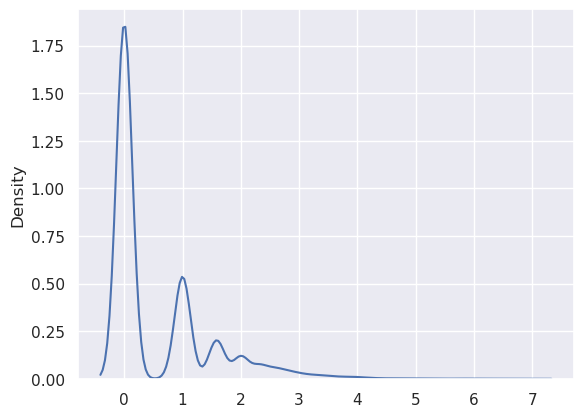

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069595__Region_2__20250822__185707/


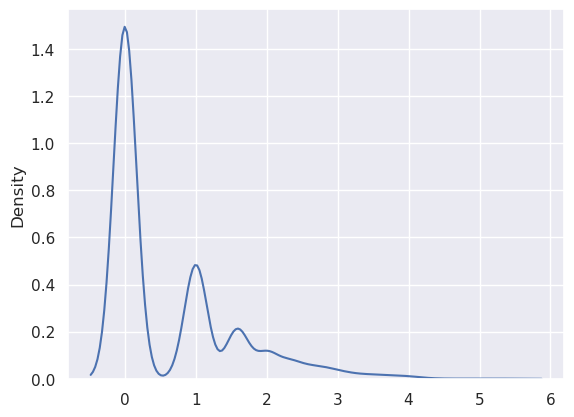

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069641__Region_1__20250808__172538/


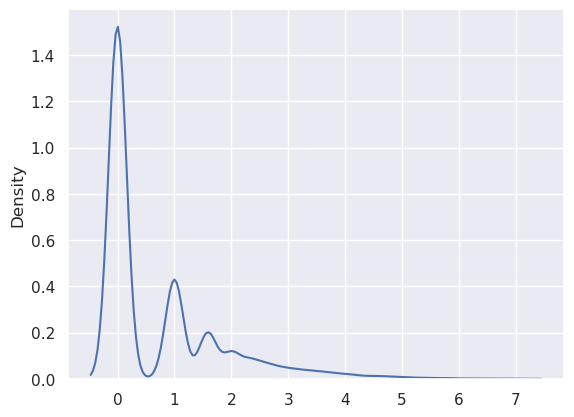

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0069641__Region_2__20250808__172538/


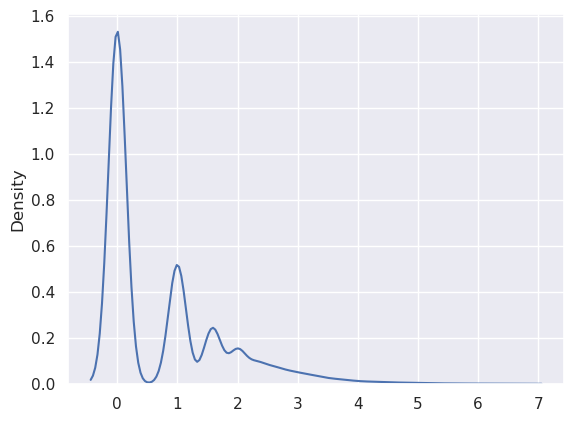

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069808__Region_1__20250904__175644/


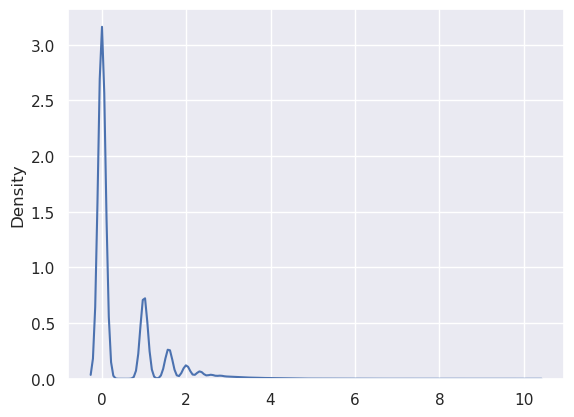

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015858__Region_2__20250904__184740/


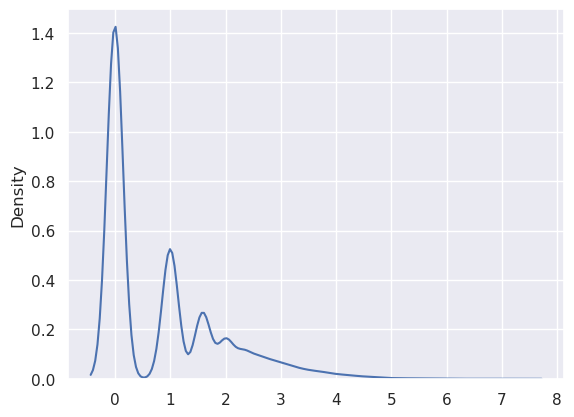

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015858__Region_1__20250904__184740/


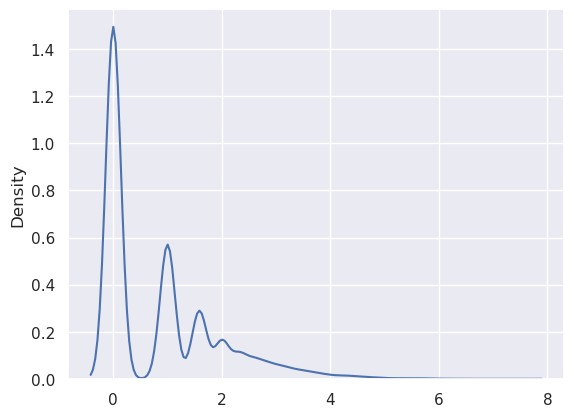

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015829__Region_1__20250904__184739/


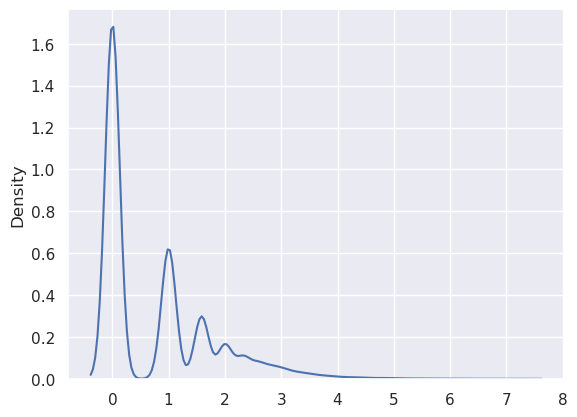

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00174__0015829__Region_2__20250904__184740/


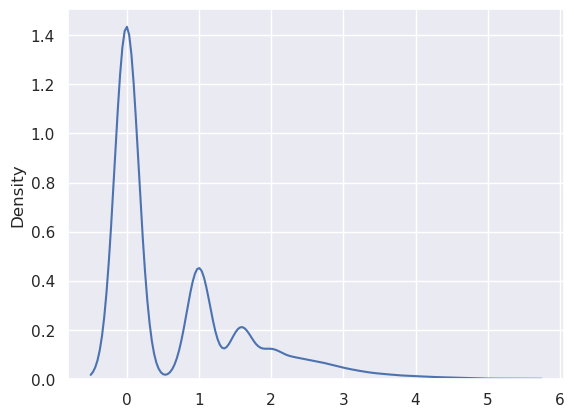

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069665__Region_2__20250904__175644/


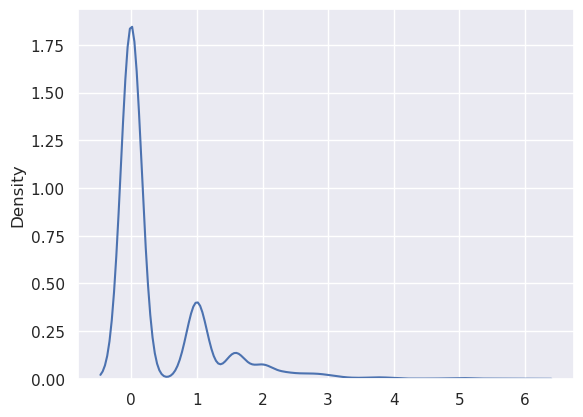

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0069665__Region_1__20250904__175644/


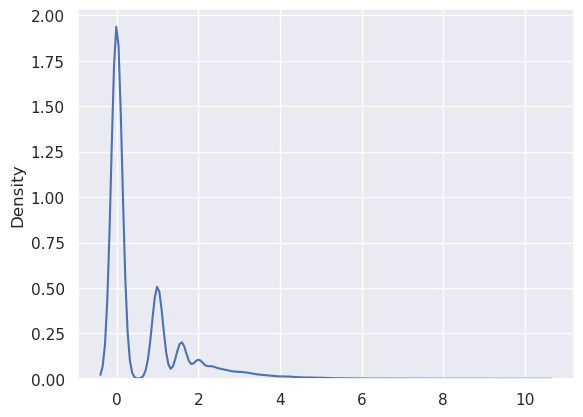

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_3__20251001__202328/


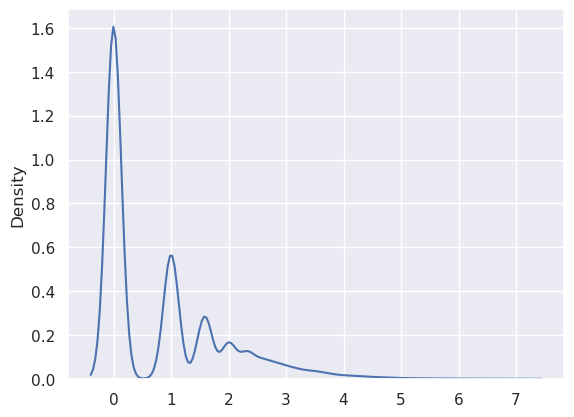

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_2__20251001__202328/


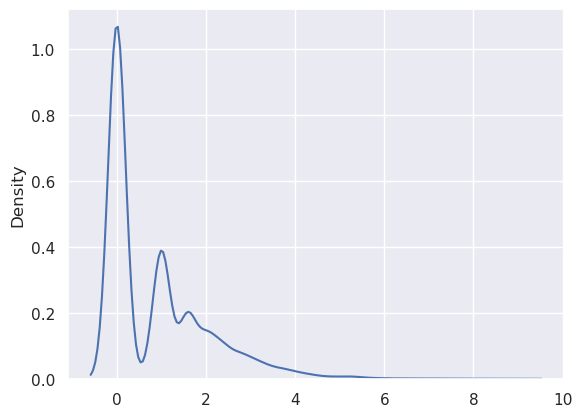

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_3__20251001__202328/


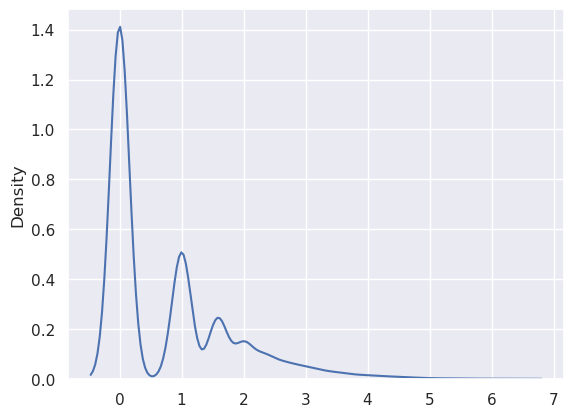

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078989__Region_1__20251001__202328/


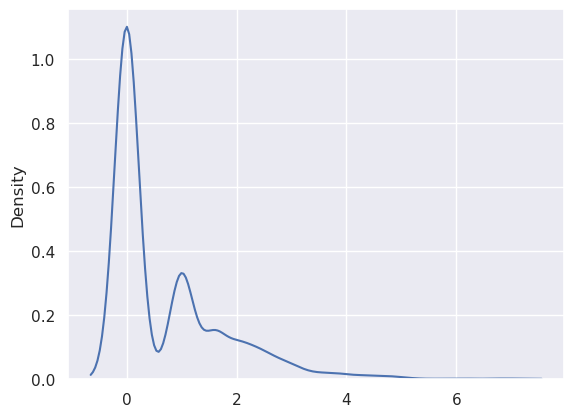

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_1__20251001__202327/


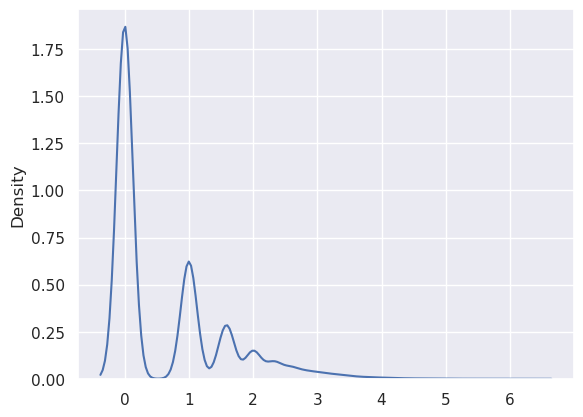

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0078981__Region_2__20251001__202328/


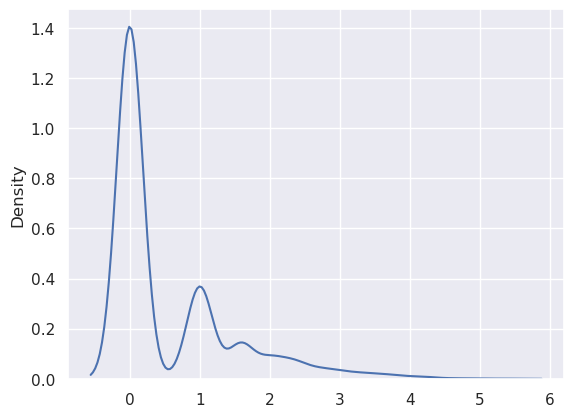

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079272__Region_1__20250926__202419/


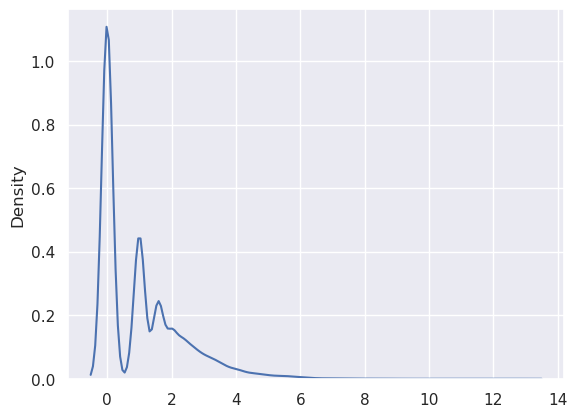

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079272__Region_2__20250926__202419/


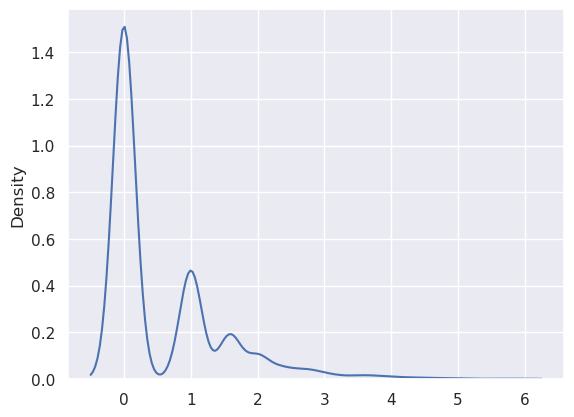

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079269__Region_2__20250926__202419/


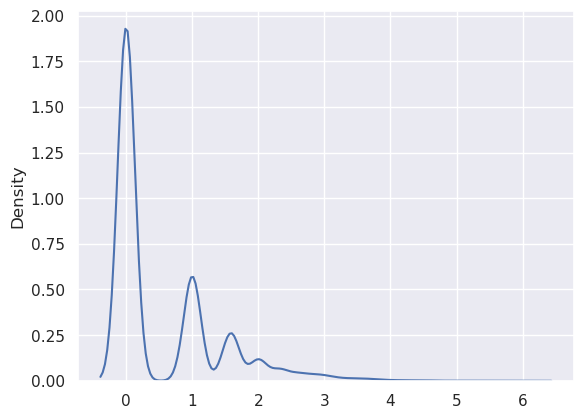

/data1/greenbab/users/zhangb2/xenium_files/review_samples/v1/output-XETG00065__0079269__Region_1__20250926__202419/


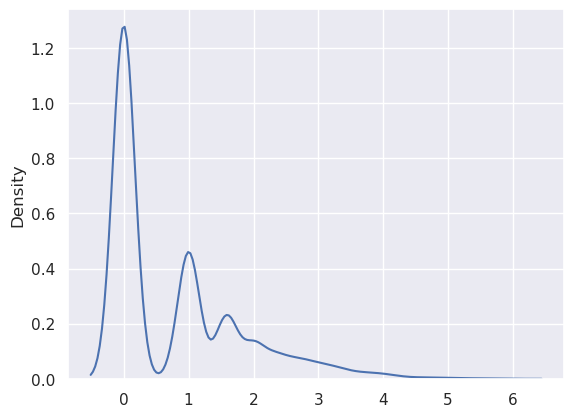

In [11]:
#### Determine cytokine clusters 
import seaborn as sns
from scipy.spatial import distance_matrix
import pandas as pd
import pickle
import anndata as ad
import scipy
from scipy.cluster.hierarchy import DisjointSet
from sklearn.neighbors import NearestNeighbors

plt.figure(figsize=(4, 4))

sample_clusts = dict()
allgenes = ['CXCL9','CXCL10','ICOSLG','IL2RA','IL1RL1','IL1R2','CXCL2','CXCL6','CXCL13','CCL19']
df = None
for currsamp in adata_xenv1.obs['sample_name'].unique():
    print(dir_di[currsamp])

    if os.path.isfile(dir_di[currsamp] + 'transcripts.csv'):
        transcripts = pd.read_csv(dir_di[currsamp] + 'transcripts.csv')
    else:
        transcripts = pd.read_csv(dir_di[currsamp] + 'transcripts.csv.gz')
        
    
    transcripts = transcripts[transcripts.qv >= 20]
    transcripts = transcripts[transcripts.feature_name.isin(['CXCL9','CXCL10','ICOSLG','IL2RA','IL1RL1','IL1R2','CXCL2','CXCL6','CXCL13','CCL19'])].reset_index()

    cytokine_clusts = runSAND_transcript(transcripts[['x_location','y_location']], 10) 
    sns.kdeplot([np.log2(len(x)) for x in cytokine_clusts])
    plt.show()
    cytokine_clusts_filtered = [x for x in cytokine_clusts if len(x) >= 10] # filter clusters with > 10 probes

    for i, clust in enumerate(cytokine_clusts_filtered):
        clust_transcripts = transcripts.iloc[[x for x in clust]]
        Counter(clust_transcripts['feature_name']) # cytokines in cluster
        currdf = pd.DataFrame([Counter(clust_transcripts['feature_name'])], columns=allgenes).fillna(0)
        currdf.index = [currsamp + '-' + str(i)]
        currdf['cells'] = ','.join(set(clust_transcripts['cell_id'])) # cells expressing cytokines
        currdf['transcripts'] = ';'.join([str(x) for x in clust_transcripts['transcript_id']])
        currdf['size'] = len(clust)
        currdf['sample'] = currsamp
        df = pd.concat([df, currdf], ignore_index=False)
    

In [17]:
tls = adata_xenv1[adata_xenv1.obs['in_tls'] == 'Yes']
df_ia = pd.crosstab(index=tls.obs['tls'], columns=tls.obs['ct_refined']).apply(lambda x: x/x.sum(), axis=1)
from collections import Counter
tls_sizes = Counter(tls.obs['tls'])
df_ia['Size'] = [tls_sizes[x] for x in df_ia.index]
df_ia['group'] = ['Small' if x < 100 else 'Large' for x in df_ia['Size']]
samptype = dict(zip(tls.obs['tls'], tls.obs['diagnosis']))
df_ia['Diagnosis'] = [samptype[x] for x in df_ia.index]
df_ia['group'] = [df_ia['Diagnosis'][i].split('-')[0] + ' ' + df_ia['group'][i] for i in range(df_ia.shape[0])]


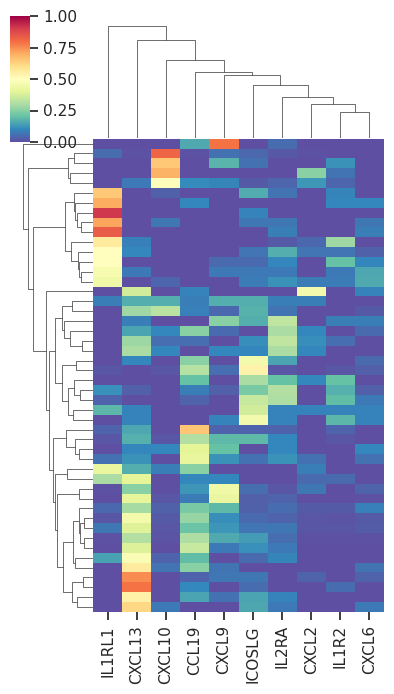

In [18]:
cyto_df = df
tmp = adata_xenv1.obs[adata_xenv1.obs["neighbor_tls"] != 'NA']
di = tmp.groupby("neighbor_tls")["cytokine_cell"].apply(set).to_dict()

curr_tls = [x for x in df_ia[df_ia['B Mature'] >= 0.33].index]
curr_clusts = [di[x] for x in curr_tls]
curr_clusts = list(set().union(*curr_clusts))

cyto_df = cyto_df.loc[[x for x in curr_clusts if not x == 'NA'],:]

cyto_df = cyto_df.iloc[:,0:10]
cyto_pct = cyto_df.div(cyto_df.sum(axis=1), axis=0)
sns.set_style("ticks")
g = sns.clustermap(cyto_pct, row_cluster=True, yticklabels=False,  xticklabels=True, cmap = 'Spectral_r', figsize=(4, 7), vmin=0, vmax=1) #row_colors=row_colors,
g.ax_heatmap.tick_params(right=False, bottom=True)
plt.show()

## Figure 3e. Enrichment near immune aggregate in MDS (log2FC heatmap with stars)


In [3]:
keep_samps = adata_xenv1[adata_xenv1.obs['in_tls'] == 'Yes'].obs['sample_name'].unique()

tmp = adata_xenv1[adata_xenv1.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
tmp = tmp[~(tmp.obs['ct_general'].isin(['T Cell', 'B Cell','NK','pDC']))]
tmp = tmp[tmp.obs['sample_name'].isin(keep_samps)]
df = pd.crosstab(index=[tmp.obs['near_TLS'], tmp.obs['study_id']], columns=[tmp.obs['ct_refined']]).apply(lambda x: x/x.sum(), axis=1)
df = df.reset_index()

rows = []
for ct in df.columns[2:]:
    fc = np.log2(df[df['near_TLS'] == 'Yes'][ct].mean() / df[df['near_TLS'] == 'No'][ct].mean())
    statistic, p_value = stats.wilcoxon(df[df['near_TLS'] == 'Yes'][ct], df[df['near_TLS'] == 'No'][ct])
    rows.append({'ct': ct, 'group': 'MDS', 'log2fc': fc, 'pval': p_value})

results_df = pd.DataFrame(rows)


In [4]:
results_df

,ct,group,log2fc,pval
0,Adipocyte,MDS,-0.294903,1.776244e-01
1,Early Myeloid,MDS,-0.997474,1.429580e-07
2,Endothelial,MDS,0.704816,7.729628e-04
3,Erythroid,MDS,-0.391014,1.950711e-04
4,HSPC,MDS,0.362874,8.609301e-01
5,Late/Mature Myeloid,MDS,-0.037314,6.915783e-01
6,Macrophage,MDS,0.945607,1.287553e-06
7,Mast,MDS,1.037610,1.180262e-02
8,Megakaryocyte,MDS,0.575162,7.333341e-03
9,Mesenchymal/Stromal,MDS,0.644475,1.802295e-05


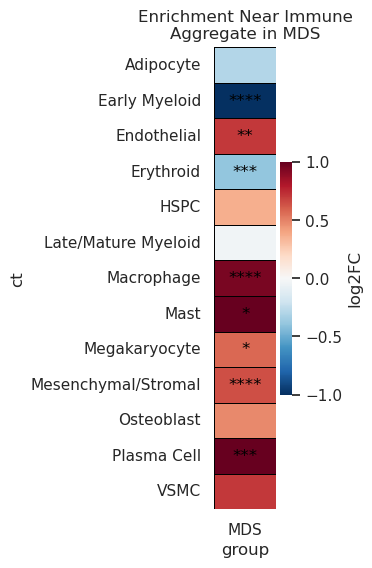

In [5]:
from statsmodels.stats.multitest import multipletests

reject, adjusted, _, _ = multipletests(results_df['pval'], alpha=0.05, method='fdr_bh')
results_df['padj'] = adjusted

# Create significance labels
def p_to_star(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return ''
results_df['label'] = results_df['padj'].apply(p_to_star)

mat = results_df.pivot(index='ct', columns='group', values='log2fc')
label_mat = results_df.pivot(index='ct', columns='group', values='label')

# Make heatmap
plt.figure(figsize=(1, 6))
sns.heatmap(
    mat, annot=label_mat, fmt='',               
    cmap='RdBu_r', center=0, vmin = -1, vmax = 1,             
    cbar_kws={'label': 'log2FC'},linewidths=0.5,
    linecolor='black', annot_kws={'color': 'black', 'fontsize':12}
)
plt.title('Enrichment Near Immune\nAggregate in MDS')
plt.grid(False)
plt.tight_layout()
plt.show()

In [6]:
results_df

,ct,group,log2fc,pval,padj,label
0,Adipocyte,MDS,-0.294903,1.776244e-01,0.238918,
1,Early Myeloid,MDS,-0.997474,1.429580e-07,0.000002,****
2,Endothelial,MDS,0.704816,7.729628e-04,0.001675,**
3,Erythroid,MDS,-0.391014,1.950711e-04,0.000634,***
4,HSPC,MDS,0.362874,8.609301e-01,0.860930,
5,Late/Mature Myeloid,MDS,-0.037314,6.915783e-01,0.749210,
6,Macrophage,MDS,0.945607,1.287553e-06,0.000008,****
7,Mast,MDS,1.037610,1.180262e-02,0.019179,*
8,Megakaryocyte,MDS,0.575162,7.333341e-03,0.013619,*
9,Mesenchymal/Stromal,MDS,0.644475,1.802295e-05,0.000078,****


## Figure 3f. DEG analysis for volcano plot: MSCs near vs far immune aggregates


In [29]:
msc = adata_xenv1[adata_xenv1.obs['ct_general'] == 'Mesenchymal/Stromal']
msc = msc[msc.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]

res = runDEseq(
    msc, 
    patient_col = 'study_id', 
    condition_col = 'near_TLS',
    cond_1 = 'No',
    cond_2 = 'Yes',
    min_cells_per_sample=25, 
    gene_filter = 0.5)

res = res.sort_values(by='padj')
res


Removing 22 unpaired samples
MDS-9_No      33921
MDS-18_No     22953
MDS-28_No     16965
MDS-35_No     12741
MDS-8_No      10071
MDS-36_No      9529
MDS-19_No      9330
MDS-2_No       8516
MDS-11_No      7945
MDS-15_No      6644
MDS-41_No      5838
MDS-24_No      5576
MDS-3_No       5158
MDS-14_No      5102
MDS-20_No      4952
MDS-1_No       4118
MDS-31_No      3940
MDS-4_No       3528
MDS-17_No      1613
MDS-9_Yes       459
MDS-35_Yes      319
MDS-28_Yes      318
MDS-8_Yes       251
MDS-14_Yes      148
MDS-24_Yes      127
MDS-20_Yes      125
MDS-18_Yes      119
MDS-31_Yes      113
MDS-11_Yes       93
MDS-2_Yes        89
MDS-1_Yes        83
MDS-15_Yes       48
MDS-4_Yes        46
MDS-36_Yes       41
MDS-3_Yes        32
MDS-41_Yes       28
MDS-17_Yes       27
MDS-19_Yes       26
Name: sample_group, dtype: int64

Retaining 38 / 38 patient-condition pairs with >= 25 cells.
19 unique patients across 38 pseudobulk rows (patient-blocked design will spend ~19 degrees of freedom on patient ide

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.36 seconds.

Fitting dispersion trend curve...
... done in 0.05 seconds.

Fitting MAP dispersions...
... done in 0.34 seconds.

Fitting LFCs...
... done in 0.39 seconds.

Refitting 0 outliers.

Running Wald tests...


Log2 fold change & Wald test p-value: near-TLS Yes vs No
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
ABCC11     1.807445        1.085901  0.637196  1.704186  0.088346       NaN
ACE2       4.321440       -0.685698  0.536760 -1.277477  0.201434       NaN
ACKR1     10.624017       -0.617510  0.377080 -1.637612  0.101503  0.180557
ACTA2     65.428475        0.207331  0.252476  0.821190  0.411538  0.514422
ACTG2    143.836437        0.066306  0.152019  0.436168  0.662715  0.725457
...             ...             ...       ...       ...       ...       ...
VCAM1   1325.542740       -0.186259  0.113509 -1.640927  0.100813  0.180197
VCAN    1857.903704       -0.301117  0.100671 -2.991107  0.002780  0.010337
VSIG4     34.768176       -0.330133  0.204534 -1.614075  0.106511  0.188561
VWA5A     37.139062       -0.065941  0.235494 -0.280010  0.779470  0.838383
VWF       28.600551       -0.838372  0.331462 -2.529316  0.011429  0.033036

[428 rows x 6 columns]


... done in 0.24 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
TRAC,139.229935,2.153262,0.141112,15.259210,1.429688e-52,5.289845e-50
CCL19,113.758266,4.788590,0.395944,12.094117,1.134557e-33,2.098930e-31
CXCL9,154.935368,2.858901,0.239876,11.918261,9.507245e-33,1.172560e-30
CD3E,68.874457,1.650183,0.155707,10.597992,3.044481e-26,2.816145e-24
IL7R,90.522979,1.749088,0.169900,10.294821,7.435812e-25,5.502501e-23
...,...,...,...,...,...,...
TFF2,1.295918,0.572205,0.718042,0.796897,4.255109e-01,NaN
TMEM174,1.641655,0.307393,0.697167,0.440917,6.592731e-01,NaN
TMEM52B,4.577568,-1.126961,0.581945,-1.936542,5.280130e-02,NaN
UMOD,1.114128,0.845916,0.737482,1.147033,2.513681e-01,NaN


## Figure 3g. DEG analysis for volcano plot: T cells near vs far immune aggregates

In [31]:
ad_t = adata_xenv1[adata_xenv1.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
ad_t = ad_t[ad_t.obs['ct_general'].isin(['T Cell'])]

t_cell_genes = ['BCL2L11', 'CCL5', 'CCR7', 'CCR8', 'CD2', 'CD244', 'CD247', 'CD27',
                'CD28', 'CD3D', 'CD3E', 'CD4', 'CD5', 'CD69', 'CD7', 'CD8A',
                'CTLA4', 'ENTPD1', 'FAS', 'FOXP3', 'GATA3', 'GNLY', 'GZMA',
                'GZMB', 'GZMK', 'HAVCR2', 'ICOS', 'IKZF2', 'IL2RA', 'IL7R',
                'ITGA6', 'KLRB1', 'KLRC1', 'KLRD1', 'KLRG1', 'LAG3', 'LEF1',
                'NKG7', 'PDCD1', 'PRF1', 'PTPRC', 'SATB2', 'SELL', 'SH2D3C',
                'SLAMF1', 'SPN', 'TBX21', 'TCF7', 'TIGIT', 'TNFRSF9', 'TOX', 'TRAC']

ad_t = ad_t[:, [g for g in t_cell_genes]] # subset to t cell genes

res = runDEseq(
    ad_t, 
    patient_col = 'study_id', 
    condition_col = 'in_tls',
    cond_1 = 'No',
    cond_2 = 'Yes',
    min_cells_per_sample=25)

res = res.sort_values(by='padj')
res

Removing 13 unpaired samples
MDS-9_No      32504
MDS-18_No     24206
MDS-8_No       9116
MDS-28_No      9017
MDS-19_No      8583
MDS-31_No      8486
MDS-11_No      5102
MDS-41_No      4925
MDS-20_No      4301
MDS-35_No      3617
MDS-2_No       3433
MDS-14_No      2903
MDS-24_No      2844
MDS-36_No      2586
MDS-9_Yes      2380
MDS-4_No       2272
MDS-34_No      2257
MDS-22_No      2255
MDS-39_No      2056
MDS-1_No       1844
MDS-7_No       1815
MDS-15_No      1682
MDS-6_No       1602
MDS-21_No      1498
MDS-20_Yes     1389
MDS-5_No       1201
MDS-35_Yes     1129
MDS-30_No      1113
MDS-28_Yes     1109
MDS-26_No      1015
MDS-8_Yes       919
MDS-24_Yes      884
MDS-31_Yes      816
MDS-3_No        715
MDS-11_Yes      712
MDS-14_Yes      623
MDS-18_Yes      568
MDS-17_No       408
MDS-41_Yes      272
MDS-2_Yes       271
MDS-3_Yes       230
MDS-1_Yes       205
MDS-21_Yes      174
MDS-15_Yes      136
MDS-36_Yes      127
MDS-4_Yes       106
MDS-30_Yes      101
MDS-19_Yes      101
MDS-34_Yes 

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.06 seconds.

Fitting dispersion trend curve...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.05 seconds.

Fitting LFCs...


Log2 fold change & Wald test p-value: in-tls Yes vs No
            baseMean  log2FoldChange     lfcSE      stat        pvalue  \
BCL2L11    97.334387       -0.021928  0.089149 -0.245971  8.057044e-01   
CCL5      879.361770       -0.315472  0.104417 -3.021272  2.517149e-03   
CCR7      191.017462        0.559230  0.131192  4.262685  2.019855e-05   
CCR8       20.195589        0.229314  0.223371  1.026603  3.046073e-01   
CD2       838.414608        0.119208  0.037481  3.180523  1.470097e-03   
CD244     103.345575       -0.872415  0.117289 -7.438197  1.020689e-13   
CD247     534.203099       -0.021986  0.035455 -0.620102  5.351906e-01   
CD27      145.196432        0.378382  0.074352  5.089073  3.598177e-07   
CD28      294.184421        0.211059  0.067603  3.122027  1.796106e-03   
CD3D      637.198091        0.072241  0.035673  2.025072  4.286002e-02   
CD3E      887.266995        0.012381  0.030117  0.411108  6.809937e-01   
CD4       291.163783        0.426813  0.064910  6.575473 

... done in 0.06 seconds.

Refitting 0 outliers.

Running Wald tests...
... done in 0.03 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
CD244,103.345575,-0.872415,0.117289,-7.438197,1.020689e-13,5.307582e-12
KLRD1,173.985221,-0.811764,0.117656,-6.899470,5.219678e-12,1.357116e-10
TRAC,1771.187397,0.217035,0.032853,6.606268,3.941287e-11,6.304822e-10
CD4,291.163783,0.426813,0.064910,6.575473,4.849863e-11,6.304822e-10
PRF1,194.955679,-0.629540,0.097810,-6.436374,1.223616e-10,1.272561e-09
NKG7,232.869264,-0.791458,0.135323,-5.848662,4.955428e-09,4.294705e-08
KLRC1,94.343589,-0.669854,0.118277,-5.663451,1.483588e-08,1.102094e-07
KLRG1,577.519767,-0.528141,0.093794,-5.630836,1.793379e-08,1.165697e-07
TCF7,583.615611,0.424074,0.076967,5.509851,3.591379e-08,2.075019e-07
GZMA,475.619585,-0.602534,0.111281,-5.414546,6.144452e-08,3.195115e-07
